<!-- LCDM_VISUALIZATIONS_SECTION_V1 -->
# ΛCDM · Background Cosmology Visualizations

**Baumann, *Cosmology*, §2.3.5–2.3.6 · Eq. (2.144), (2.148), Fig. 2.10**

Αυτό το τμήμα επεκτείνει τις προηγούμενες αναλυτικές παραγωγές των εξισώσεων Friedmann με **τέσσερα συμπληρωματικά γραφήματα**. Δεν ξανακάνουμε τις παραγωγές Christoffel, Ricci ή Friedmann.

**Συμβάσεις:** $a_0=1$, $c=1$ στις θεωρητικές εξισώσεις, $k=0$ (χωρικά επίπεδο υπόβαθρο), $
ho$ = ενεργειακή πυκνότητα σε φυσικές μονάδες. Οι παράμετροι πυκνότητας με δείκτη $0$ ορίζονται σήμερα. Οι αριθμοί είναι ενδεικτικό, αυτοσυνεπές ΛCDM κοντά στις τιμές που χρησιμοποιεί ο Baumann — όχι ανεξάρτητη νέα προσαρμογή σε δεδομένα.

### Το μαθηματικό μοντέλο

$$
\boxed{\begin{aligned}
\rho_r(a)&=\rho_{r,0}a^{-4},\\[3pt]
\rho_m(a)&=\rho_{m,0}a^{-3},\\[3pt]
\rho_\Lambda(a)&=\rho_{\Lambda,0}=\mathrm{const.}
\end{aligned}}
$$

$$
\boxed{\begin{aligned}
H^2(a)&=H_0^2\!\left[\Omega_{r,0}a^{-4}+\Omega_{m,0}a^{-3}+\Omega_{\Lambda,0}\right],\\[3pt]
E(a)&\equiv\frac{H(a)}{H_0},\qquad \Omega_{r,0}+\Omega_{m,0}+\Omega_{\Lambda,0}=1.
\end{aligned}}
$$

**Σημαντική διάκριση:** $\rho_i(a)/\rho_{\mathrm{crit},0}$ **δεν είναι** το ίδιο με το $\Omega_i(a)=\rho_i(a)/\rho_{\mathrm{crit}}(a)$. Θα σχεδιάσουμε και τα δύο χωριστά.

In [1]:
# --- 1. Standalone parameters (do not overwrite earlier notebook variables) ---
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown

lcdm_H0_km_s_Mpc = 67.74
lcdm_Or0 = 9.0e-5
lcdm_Om0 = 0.32
lcdm_Ol0 = 1.0 - lcdm_Om0 - lcdm_Or0  # flat universe: Omega_k,0 = 0

lcdm_colors = {
    'radiation': '#d79a35',
    'matter': '#297da8',
    'lambda': '#8259b5',
    'total': '#303747',
    'accent': '#177e69',
}

def lcdm_E2(a):
    a = np.asarray(a, dtype=float)
    return lcdm_Or0 * a**(-4) + lcdm_Om0 * a**(-3) + lcdm_Ol0

def lcdm_E(a):
    return np.sqrt(lcdm_E2(a))

def lcdm_fractions(a):
    d = lcdm_E2(a)
    return (lcdm_Or0 * np.asarray(a)**(-4)/d,
            lcdm_Om0 * np.asarray(a)**(-3)/d,
            lcdm_Ol0/d)

def lcdm_q(a):
    a = np.asarray(a, dtype=float)
    # q = -(a a'') / a'^2 = 1/2 [2 Omega_r(a) + Omega_m(a) - 2 Omega_Lambda(a)]
    return (2*lcdm_Or0*a**(-4) + lcdm_Om0*a**(-3) - 2*lcdm_Ol0)/(2*lcdm_E2(a))

lcdm_a_eq = lcdm_Or0 / lcdm_Om0
lcdm_a_mLambda = (lcdm_Om0/lcdm_Ol0)**(1/3)

# Unique zero of q(a): 2 Omega_r,0 + Omega_m,0 a - 2 Omega_Lambda,0 a^4 = 0.
from scipy.optimize import brentq
lcdm_a_acc = brentq(lambda a: 2*lcdm_Or0 + lcdm_Om0*a - 2*lcdm_Ol0*a**4,
                        1.0e-4, 2.0)

# Hubble time in billions of years from km/s/Mpc to Gyr.
lcdm_Mpc_km = 3.085677581491367e19
lcdm_Gyr_s = 365.25 * 24 * 3600 * 1.0e9
lcdm_H0inv_Gyr = lcdm_Mpc_km / lcdm_H0_km_s_Mpc / lcdm_Gyr_s

assert abs(lcdm_E2(1.0)-1) < 1e-12
assert abs(sum(lcdm_fractions(1.0))-1) < 1e-12

print('Flat Lambda-CDM | self-consistent parameters')
print(f'Omega_r,0 = {lcdm_Or0:.6f}    Omega_m,0 = {lcdm_Om0:.5f}')
print(f'Omega_L,0 = {lcdm_Ol0:.6f}    Omega_k,0 = 0')
print(f'H0 = {lcdm_H0_km_s_Mpc:.2f} km s^-1 Mpc^-1')
display(Math(r'\boxed{\Omega_{r,0}+\Omega_{m,0}+\Omega_{\Lambda,0}=1}'))
display(Math(r'\boxed{\frac{H^2(a)}{H_0^2}=\Omega_{r,0}a^{-4}+\Omega_{m,0}a^{-3}+\Omega_{\Lambda,0}}'))
print(f'radiation–matter equality: a_eq={lcdm_a_eq:.6g}, z_eq={1/lcdm_a_eq-1:.0f}')
print(f'matter–Lambda equality:  a_eq={lcdm_a_mLambda:.4f}, z_eq={1/lcdm_a_mLambda-1:.3f}')
print(f'acceleration begins:     a_acc={lcdm_a_acc:.4f}, z_acc={1/lcdm_a_acc-1:.3f}')

Flat Lambda-CDM | self-consistent parameters
Omega_r,0 = 0.000090    Omega_m,0 = 0.32000
Omega_L,0 = 0.679910    Omega_k,0 = 0
H0 = 67.74 km s^-1 Mpc^-1


<IPython.core.display.Math object>

<IPython.core.display.Math object>

radiation–matter equality: a_eq=0.00028125, z_eq=3555
matter–Lambda equality:  a_eq=0.7779, z_eq=0.286
acceleration begins:     a_acc=0.6176, z_acc=0.619


## Figure 1 · Cosmic energy densities

$$
\boxed{\frac{\rho_i(a)}{\rho_{\mathrm{crit},0}}=\Omega_{i,0}a^{-3(1+w_i)}}
$$

Οι τρεις καμπύλες δείχνουν **φυσικές πυκνότητες κανονικοποιημένες ως προς τη σημερινή κρίσιμη πυκνότητα**, όχι τις χρονικά μεταβαλλόμενες παραμέτρους $\Omega_i(a)$. Η ακτινοβολία κυριαρχεί στο πολύ μικρό $a$, ακολουθεί η ύλη και τελικά η ενέργεια κενού. Αριστερά είναι το παρελθόν, $a=1$ είναι σήμερα.

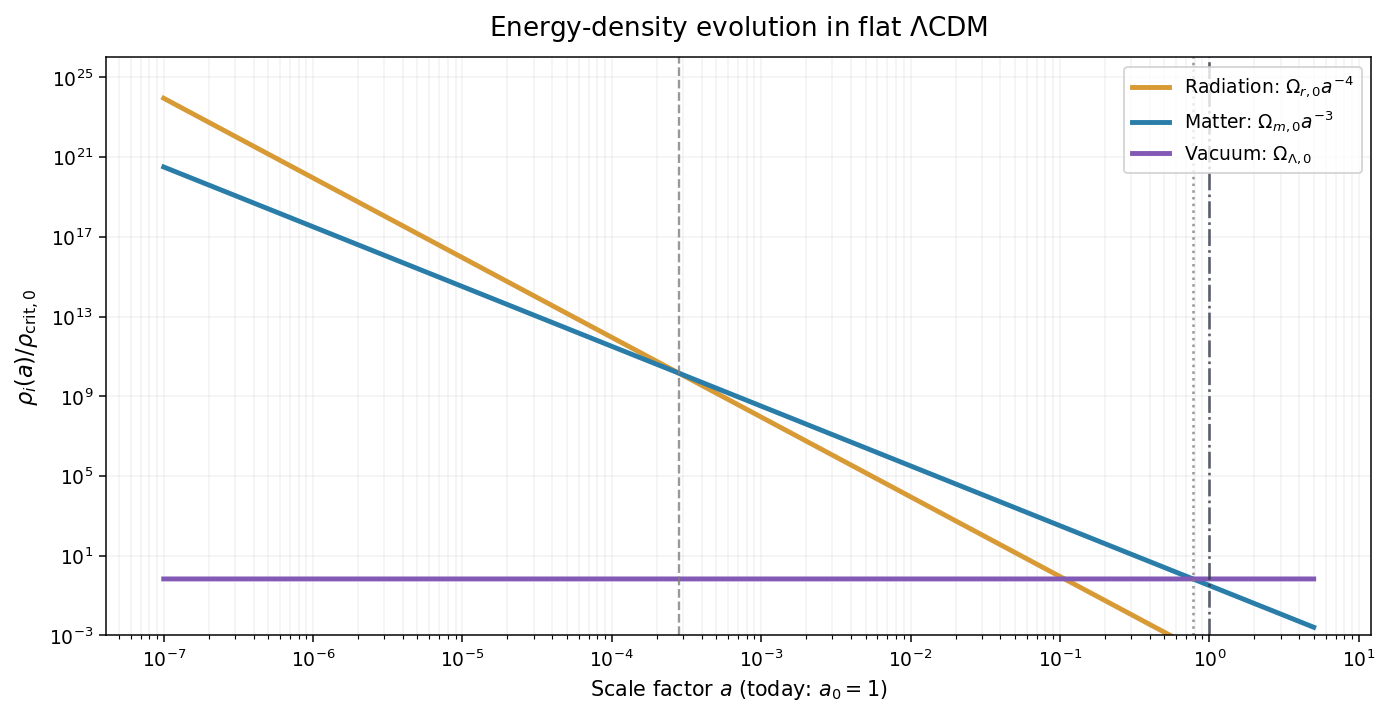

In [4]:
lcdm_a = np.logspace(-7, np.log10(5), 1500)
lcdm_rr = lcdm_Or0 * lcdm_a**(-4)
lcdm_rm = lcdm_Om0 * lcdm_a**(-3)
lcdm_rl = np.full_like(lcdm_a, lcdm_Ol0)

fig, ax = plt.subplots(figsize=(10.4, 5.4), dpi=135)
ax.loglog(lcdm_a, lcdm_rr, lw=2.6, color=lcdm_colors['radiation'], label=r'Radiation: $\Omega_{r,0}a^{-4}$')
ax.loglog(lcdm_a, lcdm_rm, lw=2.6, color=lcdm_colors['matter'], label=r'Matter: $\Omega_{m,0}a^{-3}$')
ax.loglog(lcdm_a, lcdm_rl, lw=2.6, color=lcdm_colors['lambda'], label=r'Vacuum: $\Omega_{\Lambda,0}$')
ax.axvline(lcdm_a_eq, color='gray', ls='--', lw=1.25, alpha=0.8)
ax.axvline(lcdm_a_mLambda, color='gray', ls=':', lw=1.35, alpha=0.8)
ax.axvline(1, color=lcdm_colors['total'], ls='-.', lw=1.4, alpha=0.8)
ax.set_xlabel(r'Scale factor $a$ (today: $a_0=1$)', fontsize=11)
ax.set_ylabel(r'$\rho_i(a)/\rho_{\mathrm{crit},0}$', fontsize=12)
ax.set_title(r'Energy-density evolution in flat $\Lambda$CDM', fontsize=14, pad=12)
ax.set_ylim(1e-3, 1e26)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, which='both', alpha=0.17)
fig.tight_layout()
plt.show()

## Figure 2 · Density parameters $\Omega_i(a)$

$$
\boxed{\begin{aligned}
\Omega_r(a)&=\frac{\Omega_{r,0}a^{-4}}{E^2(a)},\\[2pt]
\Omega_m(a)&=\frac{\Omega_{m,0}a^{-3}}{E^2(a)},\\[2pt]
\Omega_\Lambda(a)&=\frac{\Omega_{\Lambda,0}}{E^2(a)}.
\end{aligned}}
\qquad
\boxed{\Omega_r(a)+\Omega_m(a)+\Omega_\Lambda(a)=1}
$$

Σε αυτό το γράφημα κάθε καμπύλη δείχνει το **μερίδιο** της αντίστοιχης συνιστώσας στη συνολική πυκνότητα του επίπεδου μοντέλου τη συγκεκριμένη εποχή. Η ισότητα ακτινοβολίας–ύλης συμβαίνει όταν $a=\Omega_{r,0}/\Omega_{m,0}$, ενώ η ισότητα ύλης–Λ όταν $a=(\Omega_{m,0}/\Omega_{\Lambda,0})^{1/3}$.

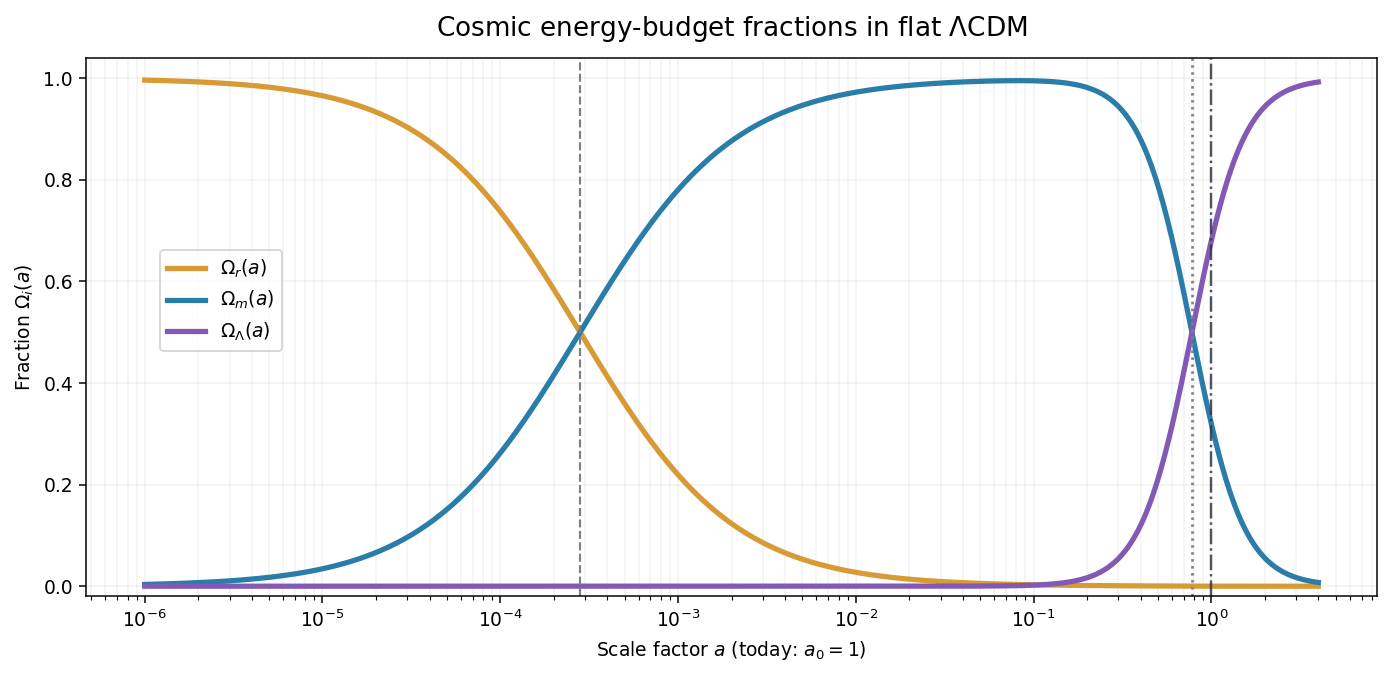

In [7]:
lcdm_a = np.logspace(-6, np.log10(4), 1300)
lcdm_fr, lcdm_fm, lcdm_fl = lcdm_fractions(lcdm_a)
fig, ax = plt.subplots(figsize=(10.4, 5.1), dpi=135)
ax.semilogx(lcdm_a, lcdm_fr, lw=2.8, color=lcdm_colors['radiation'], label=r'$\Omega_r(a)$')
ax.semilogx(lcdm_a, lcdm_fm, lw=2.8, color=lcdm_colors['matter'], label=r'$\Omega_m(a)$')
ax.semilogx(lcdm_a, lcdm_fl, lw=2.8, color=lcdm_colors['lambda'], label=r'$\Omega_\Lambda(a)$')
ax.axvline(lcdm_a_eq, ls='--', lw=1.15, color='gray')
ax.axvline(lcdm_a_mLambda, ls=':', lw=1.4, color='gray')
ax.axvline(1, ls='-.', lw=1.3, color=lcdm_colors['total'], alpha=0.85)
ax.set(xlabel=r'Scale factor $a$ (today: $a_0=1$)', ylabel=r'Fraction $\Omega_i(a)$', ylim=(-0.02, 1.04))
ax.set_title(r'Cosmic energy-budget fractions in flat $\Lambda$CDM', fontsize=14, pad=12)
ax.grid(True, which='both', alpha=0.17)
ax.legend(loc='center left', bbox_to_anchor=(0.05, 0.55), frameon=True)
fig.tight_layout()
plt.show()

## Figure 3 · Deceleration parameter and onset of acceleration

Η δεύτερη Friedmann δίνει μια απευθείας σύνδεση μεταξύ **πίεσης και επιτάχυνσης**:

$$
\boxed{\begin{aligned}
q(a)&\equiv-\frac{a\ddot a}{\dot a^{\,2}}=-\frac{\ddot a}{aH^2}\\[2pt]
&=\frac{\Omega_{m,0}a^{-3}+2\Omega_{r,0}a^{-4}-2\Omega_{\Lambda,0}}{2E^2(a)}
\end{aligned}}
$$

- $q>0$: επιβραδυνόμενη διαστολή.
- $q<0$: επιταχυνόμενη διαστολή.
- $q=0$: μετάβαση, **όχι** το ίδιο γεγονός με την ισότητα $\rho_m=\rho_\Lambda$.

Η μετάβαση $q(a_{\mathrm{acc}})=0$ ικανοποιεί $2\Omega_{r,0}+\Omega_{m,0}a_{\mathrm{acc}}-2\Omega_{\Lambda,0}a_{\mathrm{acc}}^{4}=0$.

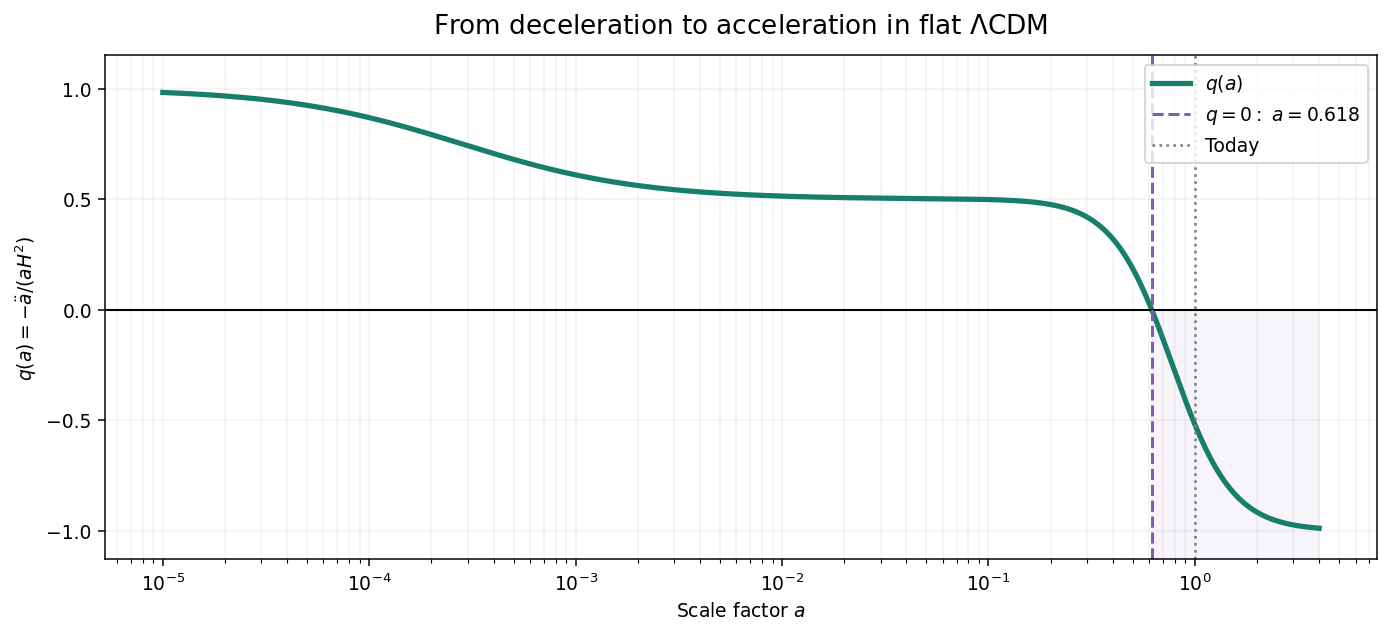

At a=1: q0 = -0.5198; onset of acceleration: z ≈ 0.619


In [10]:
lcdm_a = np.logspace(-5, np.log10(4), 1400)
fig, ax = plt.subplots(figsize=(10.4, 4.8), dpi=135)
ax.semilogx(lcdm_a, lcdm_q(lcdm_a), color=lcdm_colors['accent'], lw=2.8, label=r'$q(a)$')
ax.axhline(0, color='black', lw=1.1)
ax.axvline(lcdm_a_acc, color=lcdm_colors['lambda'], ls='--', lw=1.6,
           label=fr'$q=0:\ a={lcdm_a_acc:.3f}$')
ax.axvline(1.0, color='gray', ls=':', lw=1.4, label='Today')
ax.fill_between(lcdm_a, -1.3, 0, where=lcdm_a >= lcdm_a_acc,
                color=lcdm_colors['lambda'], alpha=0.06)
ax.set(xlabel=r'Scale factor $a$', ylabel=r'$q(a)=-\ddot a/(aH^2)$', ylim=(-1.13, 1.15))
ax.set_title(r'From deceleration to acceleration in flat $\Lambda$CDM', fontsize=14, pad=12)
ax.grid(True, which='both', alpha=0.17)
ax.legend(loc='upper right', frameon=True)
fig.tight_layout()
plt.show()
print(f'At a=1: q0 = {float(lcdm_q(1)):.4f}; onset of acceleration: z ≈ {1/lcdm_a_acc-1:.3f}')

## Figure 4 · Expansion history $a(t)$

Για το πλήρες ΛCDM με ακτινοβολία, ύλη και Λ, υπολογίζουμε αριθμητικά τον χρόνο:

$$
\boxed{\begin{aligned}
H(a)&=H_0 E(a),\\[3pt]
t(a)-t_{\mathrm{BB}}&=\frac{1}{H_0}\int_0^a\frac{da'}{a'\sqrt{\Omega_{r,0}a'^{-4}+\Omega_{m,0}a'^{-3}+\Omega_{\Lambda,0}}}.
\end{aligned}}
$$

Ο χρόνος μετριέται σε δισεκατομμύρια έτη (Gyr). Το $t_{\mathrm{BB}}=0$ αναφέρεται στο ιδανικό θερμό FLRW μοντέλο, **δεν περιγράφει** τη φάση του πληθωρισμού ή την κβαντική βαρύτητα.

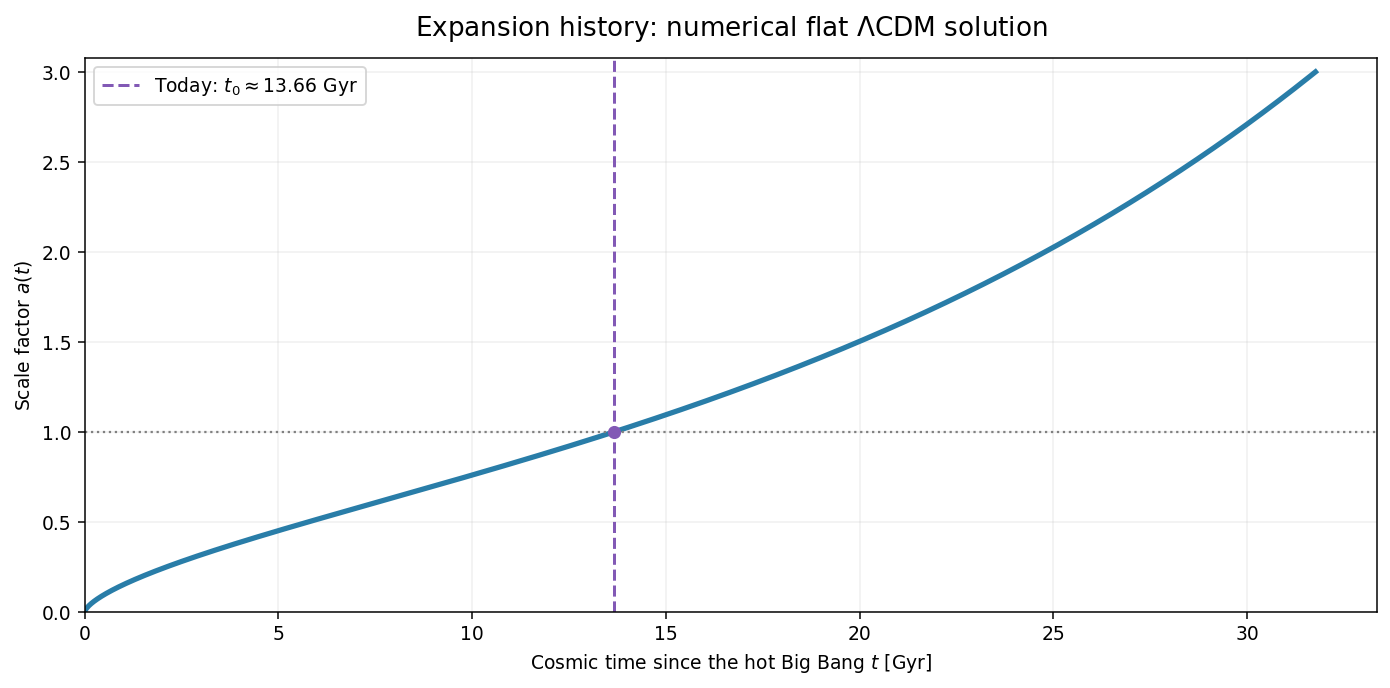

<IPython.core.display.Math object>

In [13]:
# Trapezoidal integration on a logarithmically spaced grid; no dependence on past cells.
lcdm_at = np.geomspace(1e-9, 3.0, 24000)
lcdm_integrand = 1.0 / (lcdm_at * lcdm_E(lcdm_at))
lcdm_dt = np.diff(lcdm_at) * (lcdm_integrand[1:] + lcdm_integrand[:-1]) / 2
lcdm_t_Gyr = np.r_[0, np.cumsum(lcdm_dt)] * lcdm_H0inv_Gyr
lcdm_t0_Gyr = float(np.interp(1.0, lcdm_at, lcdm_t_Gyr))

fig, ax = plt.subplots(figsize=(10.4, 5.2), dpi=135)
ax.plot(lcdm_t_Gyr, lcdm_at, color=lcdm_colors['matter'], lw=2.8)
ax.axvline(lcdm_t0_Gyr, color=lcdm_colors['lambda'], ls='--', lw=1.6,
           label=fr'Today: $t_0\approx {lcdm_t0_Gyr:.2f}$ Gyr')
ax.axhline(1, color='gray', ls=':', lw=1.2)
ax.plot([lcdm_t0_Gyr], [1], 'o', color=lcdm_colors['lambda'], ms=6)
ax.set(xlabel=r'Cosmic time since the hot Big Bang $t$ [Gyr]',
       ylabel=r'Scale factor $a(t)$', xlim=(0, None), ylim=(0, 3.08))
ax.set_title(r'Expansion history: numerical flat $\Lambda$CDM solution', fontsize=14, pad=12)
ax.grid(True, alpha=0.2)
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()
display(Math(fr'\boxed{{t_0\simeq {lcdm_t0_Gyr:.2f}\ \mathrm{{Gyr}}\,,\qquad q_0\simeq {float(lcdm_q(1)):.3f}}}'))

### Key conclusions / Σημεία που κρατάμε

1. **Φυσικές πυκνότητες:** $\rho_r\propto a^{-4}$, $\rho_m\propto a^{-3}$, $\rho_\Lambda=\mathrm{const}$. Γι’ αυτό αλλάζει το κυρίαρχο συστατικό.
2. **Ποσοστά:** $\Omega_i(a)=\rho_i(a)/\rho_{\mathrm{crit}}(a)$, άρα διαφέρουν από τις καμπύλες των κανονικοποιημένων φυσικών πυκνοτήτων.
3. **Επιτάχυνση:** $q(a)<0$ όταν η αρνητική πίεση της Λ υπερισχύει ως προς την εξίσωση επιτάχυνσης. Η μετάβαση δεν συμπίπτει με την ισότητα ύλης–Λ.
4. **Χρόνος:** $t(a)=H_0^{-1}\int_0^a da'/(a'E(a'))$. Η αριθμητική ολοκλήρωση μάς δίνει την ιστορία της διαστολής.

**Next lesson:** thermal history and CMB. Σε αυτό το επίπεδο δεν ενσωματώνουμε ακόμη perturbations, inflation ή primordial gravitational waves.